# Do CV-parser errors reach the selection? A fairness audit of the Adecco reverse matching

**AI Ethics, Module 2 – Hiring CV Bias** · Francesco Baiocchi, Leonardo Petrilli

## Phase 3 – Do the parser's errors reach the selection? (RQ1)

Phase 2 (`phase2_protocol`) fixed the outcome: a candidate is selected for a job if they are in the top half of the
job's candidates, ranked by score, with ties drawn at random. Here we compare the selection made with the parser's
profile (O) and with the corrected one (C), group by group:

* **3.1** What does the correction change, and for which groups?
* **3.2** Independence: are all groups selected at the same rate?
* **3.3** Separation: does the parser make the same errors (false negatives, false positives) in every group?
* **3.4** Sufficiency: given the parser's decision, is a candidate confirmed by the corrected profile at the same
  rate in every group?
* **3.5** Does the answer hold for a stricter selection, the top 3?

The groups are the values of the sensitive attributes `Gender`, `Location` and their intersection `group`. Each group
is compared with a reference group, which plays the role of the privileged group in the metrics: `Male`, `NORTH` and
`Male_NORTH`. Adecco's score appears only in 3.2, as the real system: it was computed on the profile P, partly entered
by hand (phase 1, section 1.4), so it cannot show the effect of the parser.

All shares in the tables are percentages.

In [ ]:
%load_ext autoreload
%autoreload 2

import warnings

import matplotlib.pyplot as plt
import polars as pl

%matplotlib inline
warnings.filterwarnings("ignore")

pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(30)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_hide_column_data_types(True)
pl.Config.set_tbl_hide_dataframe_shape(True)

polars.config.Config

In [ ]:
from hiring_cv_bias.fairness.protocol import (
    SCORES,
    add_outcomes,
    filter_protocol,
    load_pairs,
)

df = add_outcomes(filter_protocol(load_pairs()), SCORES)
print(f"protocol pairs: {df.height:,}, candidates: {df['CANDIDATE_ID'].n_unique():,}")

protocol pairs: 36,760, candidates: 6,510


### 3.1 What the correction changes

We follow the correction in three steps: the candidates, their pairs, and the pairs whose outcome changes.

**Candidates.** For each field read by the parser (licenses, languages, job titles in `experience`), the table counts
the candidates who get at least one item the parser had missed, their share of the 6,510 protocol candidates, and the
items added in all.

In [ ]:
from hiring_cv_bias.config import profile_path
from hiring_cv_bias.fairness.metrics import for_display, profile_corrections

profiles = {v: pl.read_parquet(profile_path(v)) for v in ("O", "C")}
corrections = profile_corrections(
    profiles["O"], profiles["C"], df["CANDIDATE_ID"].unique()
)
display(for_display(corrections))

field,candidates_corrected,share_of_candidates,items_added
"""licenses""",2174,33.4,2174
"""languages""",2675,41.1,4833
"""experience""",4041,62.1,7679


Job titles are corrected for the most candidates (62.1%), then languages (41.1%) and licenses (33.4%). A corrected
candidate gets exactly one license, but more than one language or title on average (4,833 languages for 2,675
candidates, 7,679 titles for 4,041).

**Pairs.** A candidate has one pair per job. For each group, the table gives the share of its pairs where the
correction changes `Card_match`, `Languages_match`, the estimated `Experience` (by more than 0.01) and the score.

In [ ]:
from hiring_cv_bias.fairness.metrics import parser_changes

display(for_display(parser_changes(df)))

attribute,group,pairs,Card_match,Languages_match,Experience,score
"""Gender""","""Female""",17489,9.1,6.8,15.6,30.6
"""Gender""","""Male""",19271,9.4,6.5,20.9,34.2
"""Location""","""NORTH""",29144,9.7,6.6,18.0,32.4
"""Location""","""CENTER""",3300,8.6,7.3,20.5,34.7
"""Location""","""SOUTH""",4316,6.8,6.4,19.5,31.6
"""group""","""Female_NORTH""",13798,9.6,7.2,15.1,30.5
"""group""","""Male_NORTH""",15346,9.8,6.1,20.6,34.1
"""group""","""Female_CENTER""",1669,7.5,5.6,18.5,32.2
"""group""","""Male_CENTER""",1631,9.6,9.0,22.5,37.3
"""group""","""Female_SOUTH""",2022,7.0,5.6,16.9,29.7


A license or a language counts only when the job asks for it (phase 1, section 1.2), so `Card_match` and
`Languages_match` change in at most 9.8% and 9.0% of a group's pairs. The score changes in about one pair in three in
every group, from 29.7% (`Female_SOUTH`) to 37.3% (`Male_CENTER`). The South has fewer `Card_match` changes than the
North (6.8% against 9.7%) and more `Experience` changes (19.5% against 18.0%). This table has no intervals: whether such
differences reach the selection is measured in 3.2 and 3.3.

**Pairs that change outcome.** Now we keep only the pairs whose outcome changes from O to C (`changed_pairs`). The
columns are the same as above, but each share is among these pairs (a pair can have more than one change).
`other` is the share whose score changes only through an `Experience` move of 0.01 or less, and
`score_unchanged` the share whose own score does not change at all.

In [ ]:
from hiring_cv_bias.fairness.metrics import SCORE_CHANGED, outcome_change_sources

display(for_display(outcome_change_sources(df)))
changed = df.filter(pl.col("top_half_O") != pl.col("top_half_C"))
same_score = changed.filter(~SCORE_CHANGED)
print(
    f"pairs whose outcome changes: {changed.height:,} of {df.height:,} "
    f"({changed.height / df.height:.1%})"
)
print(
    f"  with the same score: {same_score.height:,} "
    f"({same_score['top_half_C'].sum()} enter the top half, "
    f"{(~same_score['top_half_C']).sum():,} leave it)"
)
print(f"pairs whose score goes down with C: {(df['score_C'] < df['score_O']).sum()}")

attribute,group,changed_pairs,Card_match,Languages_match,Experience,other,score_unchanged
"""Gender""","""Female""",1479,18.2,10.8,37.5,2.5,42.3
"""Gender""","""Male""",1739,16.6,9.1,43.3,2.4,41.3
"""Location""","""NORTH""",2438,18.0,10.0,40.3,2.3,41.9
"""Location""","""CENTER""",293,14.3,12.6,46.8,2.0,38.9
"""Location""","""SOUTH""",487,15.8,7.2,38.8,3.3,43.1
"""group""","""Female_NORTH""",1119,19.5,11.5,36.7,2.4,41.4
"""group""","""Male_NORTH""",1319,16.7,8.8,43.3,2.2,42.3
"""group""","""Female_CENTER""",112,10.7,14.3,46.4,3.6,41.1
"""group""","""Male_CENTER""",181,16.6,11.6,47.0,1.1,37.6
"""group""","""Female_SOUTH""",248,15.7,5.6,37.1,2.4,47.2


pairs whose outcome changes: 3,218 of 36,760 (8.8%)
  with the same score: 1,345 (0 enter the top half, 1,345 leave it)
pairs whose score goes down with C: 0


The correction changes the outcome of 3,218 pairs, 8.8% of the total. In every group the most common cause is a new
job title (`Experience`, 36.7% to 47.0% of the changed pairs), then a license (10.7% to 19.5%) and a language (5.6% to
14.3%). A few pairs (`other`, 1.1% to 4.2%) move only through an `Experience` change smaller than 0.01: a
shift of the score below 0.02 is enough to pass a competitor with the same or almost the same score.

Four of these pairs in ten change nothing of their own: 1,345 of the 3,218 (37.6% to 47.2% per group) keep the same
score. The correction only adds information, so no score goes down, and all 1,345 leave the top half. They are
candidates overtaken by a competitor of the same job whose CV was corrected: with O they had a place only because the
parser had missed something in that competitor's CV.

### 3.2 Independence: selection rates per group

Independence (statistical parity) asks the selection rate P(D = 1 | A = a) to be the same in every group a, where
D = 1 means selected and A is the sensitive attribute. For each score we compare every group with its reference group
in two ways:

* `spd_<score>`, the statistical parity difference: the group's rate minus the reference rate (0 means parity);
* `di_<score>`, the disparate impact: the group's rate divided by the reference rate (1 means parity).

Rates are computed over pairs, the unit fixed in phase 2: each pair is one decision, so a candidate who appears in
several jobs counts once for each job.

**Intervals.** A group has a few hundred to a few thousand candidates, so its numbers are uncertain. We measure this
with a bootstrap: 1,000 times, we draw the candidates again with replacement (a candidate drawn twice counts twice),
draw the ties again and recompute every number. The 95% interval holds the middle 95% of the 1,000 values. We draw
candidates, not pairs: the pairs of a candidate share the same profile and group, so they are not independent, and
drawing them one by one would count them as separate evidence and make the intervals too narrow. If the interval of an
SPD contains 0, or that of a DI contains 1, the data show no difference.

The figure shows the rates with their intervals; the dashed line is the rate of all pairs. SPD, in percentage
points, and DI, a ratio, are quoted in the text with their intervals.

In [ ]:
from hiring_cv_bias.fairness.metrics import bootstrap, parser_effect, selection_rates

results = bootstrap(
    df,
    {
        "rates": selection_rates,
        "effect": parser_effect,
        "effect_top3": lambda d: parser_effect(d, outcome="top3"),
    },
)

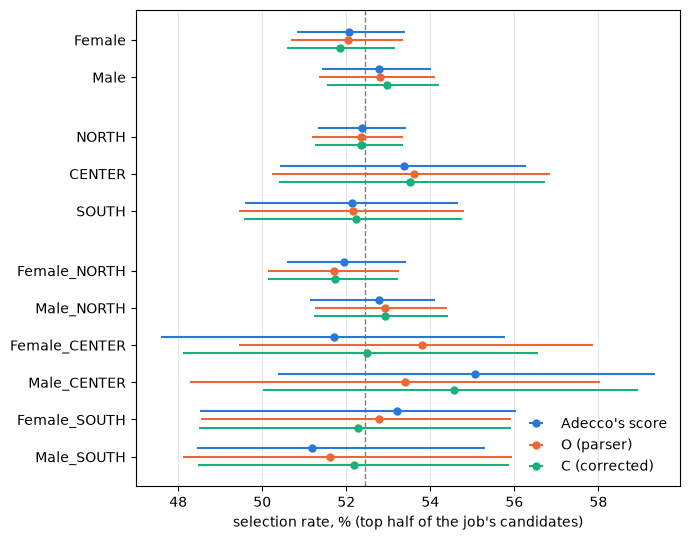

In [ ]:
from hiring_cv_bias.fairness.plots import plot_selection_rates

rates = results["rates"]
plot_selection_rates(rates, overall=df["top_half_O"].mean())
plt.show()

Every SPD is between −1.6 and +2.3 points and every DI between 0.97 and 1.04, with Adecco's score, with O and with C;
every SPD interval contains 0 and every DI interval contains 1. Women are selected 0.7 points less often than men
with Adecco's score, 0.8 with O and 1.1 with C (DI 0.99, 0.99 and 0.98). The lowest bound of any DI is 0.90, well
above the 0.8 of the four-fifths rule. The data show no violation of independence, before or after the correction.

### 3.3 Separation: the parser's errors per group

To measure the parser's errors we take the outcome with the corrected profile as the label Y and the outcome with the
parser's profile as the decision D. C is not the truth: it holds what our extractors recovered from the CV text, so
the errors below are errors of O relative to C.

* **False negative** (D = 0, Y = 1): a pair selected with C that O leaves out. `fnr` = P(D = 0 | Y = 1, A = a).
* **False positive** (D = 1, Y = 0): a pair that O selects and C does not. `fpr` = P(D = 1 | Y = 0, A = a).

Separation (equalized odds) asks both rates to be the same in every group: `fnr_diff` and `fpr_diff` are the gaps from
the reference group. `rate_change`, the rate with C minus the rate with O, tells whether a group gains places when the
parser is corrected. Every job selects the same number of candidates with O and with C, so a group can have
`rate_change` = 0 and still many errors, if it has as many false negatives as false positives. The figure shows
`rate_change` and the two gaps; the dashed line is 0.

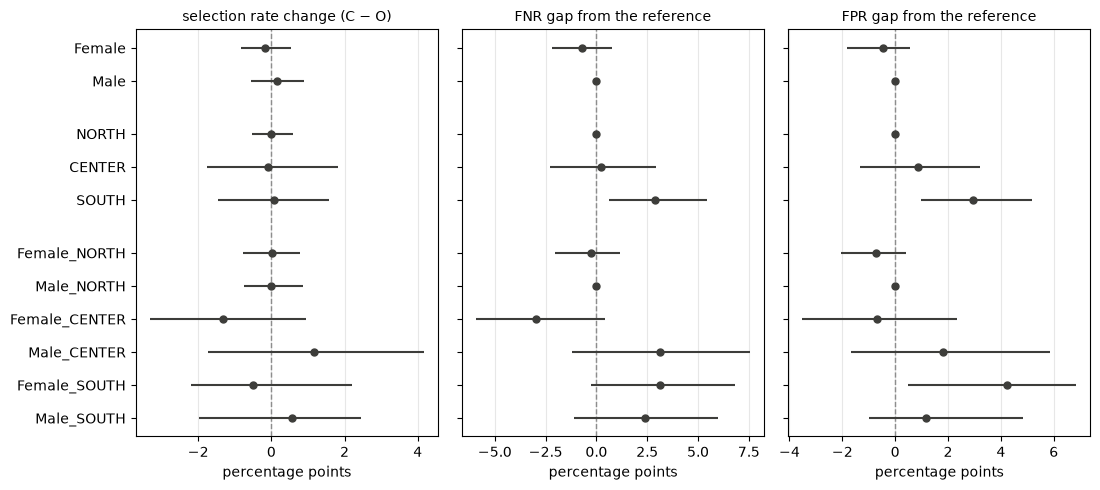

In [ ]:
from hiring_cv_bias.fairness.plots import plot_parser_effect

effect = results["effect"]
plot_parser_effect(effect)
plt.show()

**Places.** Every `rate_change` interval contains 0; the largest values are −1.3 points for `Female_CENTER` and +1.2
for `Male_CENTER`. Correcting the parser does not move places from one group to another.

**Errors.** The South is the only area where the parser's errors differ from the North, and in both directions:

* FNR: O leaves out 10.9% of the southern pairs selected with C, against 8.0% in the North (gap 2.9 points);
* FPR: O selects 11.7% of the southern pairs not selected with C, against 8.8% (gap 3.0).

False negatives and false positives cancel in the count, so `rate_change` is 0, but more southern decisions are wrong.
Among the six intersectional groups, the only gap whose interval excludes 0 is the FPR of `Female_SOUTH`: 13.4%
against 9.1% for `Male_NORTH` (gap 4.2), so equalized odds fails for this group too, through
the FPR. Between women and men there is no gap.

### 3.4 Sufficiency: how reliable the parser's decision is, per group

Sufficiency (calibration) conditions the other way round: it fixes the decision and asks whether the true outcome
depends on the group. For a binary decision it is two equalities, the positive predictive value P(Y = 1 | D = 1, A = a),
the share of the pairs O selects that C confirms (`ppv`), and the negative predictive value P(Y = 0 | D = 0, A = a), the
share of the pairs O rejects that C confirms (`npv`). Separation compares the rows of the confusion matrix (given the
true outcome, how the parser decides), sufficiency its columns (given the parser's decision, how often it is right).
The figure shows the gaps of the two values from the reference group (`ppv_diff`, `npv_diff`); the dashed line is 0.

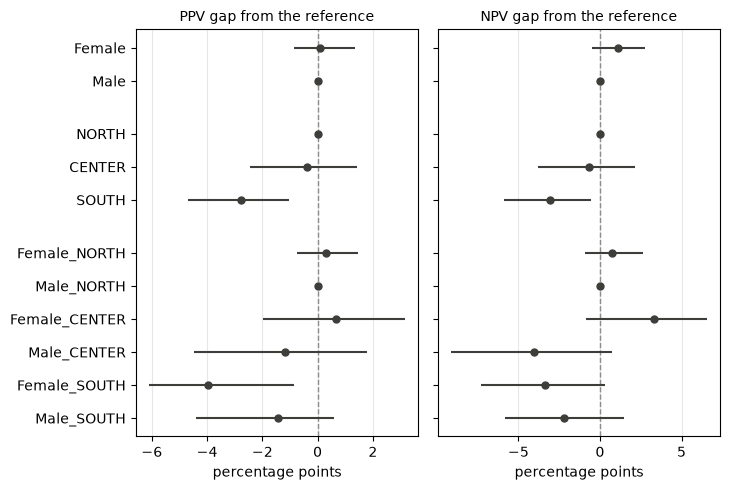

In [ ]:
from hiring_cv_bias.fairness.plots import SUFFICIENCY_PANELS

plot_parser_effect(effect, SUFFICIENCY_PANELS)
plt.show()

Both predictive values are above 86% in every group: when the parser's profile selects a candidate, the corrected one
confirms it about nine times in ten, and the same for a rejection.

The South is again the only area that differs from the North, and on both sides: O's selections are confirmed by C in
89.2% of the southern pairs against 92.0% in the North (gap −2.8), its rejections in 88.1% against 91.2% (gap −3.1), and
both intervals exclude 0. Among the intersectional groups, women from the South have a lower PPV (87.9% against 91.9%
for `Male_NORTH`, gap −4.0); their NPV gap (−3.3) and every other gap include 0. Between women and men there is no gap.

So the South fails all three criteria: it is selected at the same rate (3.2), but O's decisions on southern candidates
are wrong more often in both directions (3.3) and, read from the decision's side, confirmed less often (3.4).

### 3.5 The same with the top 3

A stricter selection: the first three candidates of every job. The table repeats `rate_change`, `fnr_diff` and
`fpr_diff` of 3.3 and `ppv_diff` and `npv_diff` of 3.4 with `top3` as the outcome.

In [ ]:
display(
    for_display(
        results["effect_top3"],
        ["rate_change", "fnr_diff", "fpr_diff", "ppv_diff", "npv_diff"],
    )
)

attribute,group,pairs,rate_change,fnr_diff,fpr_diff,ppv_diff,npv_diff
"""Gender""","""Female""",17489,"""0.2 [-0.3, 0.9]""","""-0.6 [-2.7, 2.0]""","""-0.7 [-1.6, -0.1]""","""2.0 [0.4, 4.1]""","""0.1 [-0.8, 0.9]"""
"""Gender""","""Male""",19271,"""-0.2 [-0.9, 0.4]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""Location""","""NORTH""",29144,"""0.0 [-0.5, 0.4]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""Location""","""CENTER""",3300,"""0.0 [-1.9, 1.9]""","""2.7 [-1.8, 6.7]""","""2.4 [0.5, 4.1]""","""-2.7 [-5.8, 1.1]""","""-2.4 [-4.5, -0.2]"""
"""Location""","""SOUTH""",4316,"""0.0 [-1.2, 1.3]""","""4.6 [1.2, 8.8]""","""0.5 [-0.5, 1.7]""","""-4.7 [-8.7, -1.7]""","""-0.4 [-1.8, 0.7]"""
"""group""","""Female_NORTH""",13798,"""0.3 [-0.3, 1.0]""","""0.2 [-2.2, 2.7]""","""-0.6 [-1.5, 0.2]""","""1.7 [-0.2, 3.8]""","""-0.2 [-1.2, 0.7]"""
"""group""","""Male_NORTH""",15346,"""-0.3 [-1.0, 0.3]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]""","""0.0 [0.0, 0.0]"""
"""group""","""Female_CENTER""",1669,"""-0.6 [-2.5, 1.9]""","""-1.4 [-6.4, 4.0]""","""0.9 [-1.5, 2.6]""","""0.7 [-2.5, 5.7]""","""-0.5 [-3.3, 1.8]"""
"""group""","""Male_CENTER""",1631,"""0.7 [-2.8, 3.9]""","""7.1 [0.0, 14.1]""","""3.3 [0.7, 6.4]""","""-4.5 [-10.5, 0.8]""","""-4.6 [-8.1, -1.1]"""
"""group""","""Female_SOUTH""",2022,"""0.4 [-1.3, 2.5]""","""5.6 [0.4, 12.2]""","""-0.1 [-1.7, 1.4]""","""-3.1 [-8.0, 1.5]""","""-0.8 [-3.1, 0.9]"""


Every `rate_change` interval still contains 0, and the higher FNR of the South remains: 4.6 points more than the North.
The higher FPR does not (0.5 points). Four separation gaps exclude 0 here but not in 3.3: the FPR is higher for `CENTER` (2.4 points) and `Male_CENTER` (3.3) and lower for women (−0.7), and the FNR is
higher for `Female_SOUTH` (5.6); the FNR gap of `Male_CENTER` (7.1) has 0 as its lower bound.

For sufficiency, the lower PPV of the South remains (−4.7 points) while its NPV gap does not (−0.4): with three places
per job, the pairs O rejects are almost all confirmed in every group, and the groups differ only on the pairs it selects.
Four sufficiency gaps exclude 0 here but not in 3.4: the NPV is lower for `CENTER` (−2.4) and `Male_CENTER` (−4.6), the
PPV is higher for women (+2.0) and lower for `Male_SOUTH` (−4.6); the lower PPV of `Female_SOUTH` seen in 3.4 does not
hold here (−3.1).

**Many comparisons.** 3.3 to 3.5 hold 64 gaps (8 groups × 4 rates × 2 outcomes). At the 95% level, about three
of them would exclude 0 by chance alone. So a gap seen with only one outcome is weak evidence; the ones seen with both are
the higher FNR and the lower PPV of the South.

### Findings for RQ1

* **The parser's errors reach the selection.** Correcting them changes the score of about one pair in three and the
  outcome of 8.8% of the pairs. A new job title is the most common cause, and four in ten of the pairs that change
  outcome are candidates overtaken by a corrected competitor (3.1).
* **Independence is not violated.** No group is selected at a different rate from its reference group, with O or
  with C: every SPD interval contains 0 and every DI interval contains 1 (3.2). No group gains or loses places when the
  parser is corrected (3.3, 3.5).
* **Separation is violated for the South, and for women from the South in particular.** O has a higher false
  negative rate for southern pairs than for northern ones (10.9% against 8.0%) and a higher false positive rate (11.7%
  against 8.8%); the higher FNR holds with the top 3 too (3.5). Women from the South violate equalized odds through the
  FPR with the top half (4.2 points) and through the FNR with the top 3 (5.6, section 3.5). Their gaps have the same size as the
  South's, and within the South women and men differ little (FNR 3.1 against 2.4, FPR 4.2 against 1.2), so we read
  them as the South's effect rather than an additional one for women.
* **Sufficiency is violated for the South too.** Given the parser's decision, a southern pair is confirmed by the
  corrected profile less often than a northern one: 89.2% of O's selections against 92.0%, and 88.1% of its rejections
  against 91.2% (3.4); the lower PPV holds with the top 3 (3.5).
* **No gender gap.** Women and men have the same error rates (FNR 8.0% against 8.7%, FPR 9.0% against 9.4%) and
  predictive values (PPV 91.7% against 91.6%, NPV 91.4% against 90.3%) overall, every gap within its interval, and
  within each area: the gaps of women and men of the same area have overlapping
  intervals, which are wide for the smaller groups (the 6-point FNR difference in the Centre comes from the two
  smallest groups).